# From Linear Models to Neural Networks

## Learning Objectives

Module 1 established the basic training loop:

```text
data
→ model
→ prediction
→ loss
→ gradient
→ optimizer
→ parameter update
```

The next question is:

> What happens when the relationship we want to learn cannot be represented by a single linear transformation?

In this notebook we will:

- build a nonlinear dataset
- show the limitation of a linear model
- introduce hidden layers
- understand why activation functions are necessary
- build a small neural network from tensors
- inspect tensor shapes explicitly
- train it using autograd
- compare the manual network with `nn.Module`
- visualize what the network learned

The central idea is:

```text
linear transformation
+
nonlinearity
+
linear transformation
=
basic neural network
```

The training mechanics remain the same as Module 1.

What changes is the model's **capacity to represent functions**.


In [1]:
import torch
import torch.nn as nn
import torch.optim as optim
import matplotlib.pyplot as plt

# Reproducibility
torch.manual_seed(42)

print("PyTorch:", torch.__version__)

PyTorch: 2.14.1


## A Problem a Linear Model Cannot Represent Well

A linear regression model has the form:

$$
\hat{y} = wx + b
$$

No matter how we train `w` and `b`, the prediction remains a straight line.

To motivate neural networks, we need a relationship that is genuinely nonlinear.

We will generate data approximately from:

$$
y = x^2 + \epsilon
$$

where $\epsilon$ is random noise.

The underlying relationship is curved:

```text
        •           •
         •         •
          •       •
           •     •
            •   •
             •
              •
```

A straight line cannot represent this shape well.

This gives us a controlled way to answer:

> What does adding a hidden layer and nonlinear activation actually buy us?

In [2]:
# 200 examples with one input feature each
x = torch.linspace(-3, 3, 200).reshape(-1, 1)

# Add moderate random noise
noise = 0.35 * torch.randn(200, 1)

# Nonlinear ground-truth relationship
y = x ** 2 + noise

print("x shape:", x.shape)
print("y shape:", y.shape)

x shape: torch.Size([200, 1])
y shape: torch.Size([200, 1])


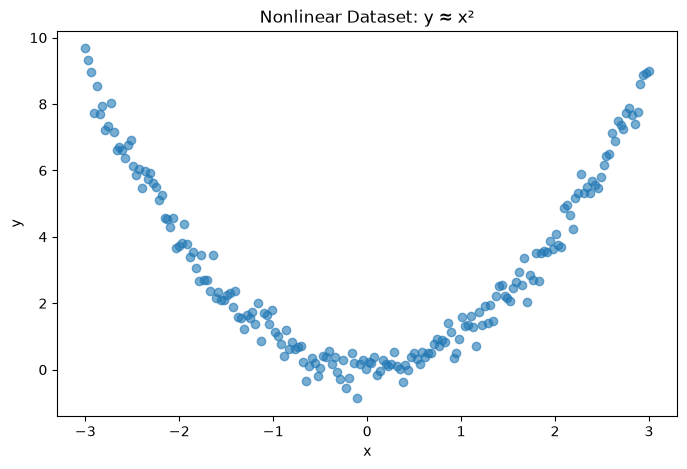

In [3]:
plt.figure(figsize=(8, 5))

plt.scatter(
    x.numpy(),
    y.numpy(),
    alpha=0.6
)

plt.xlabel("x")
plt.ylabel("y")
plt.title("Nonlinear Dataset: y ≈ x²")
plt.show()

## First Hypothesis: Try a Linear Model

Before building a neural network, we should establish a baseline.

The linear model is:

$$
\hat{y} = wx + b
$$

It has only two learnable parameters:

```text
w → slope
b → intercept
```

Because its output is always a straight line, we expect:

```text
optimization may succeed
but
representation may still fail
```

This introduces an important distinction:

```text
optimization problem
vs
model-capacity problem
```

A model can be perfectly optimized and still perform poorly if the function it
needs to learn is outside the set of functions it can represent.

In [4]:
torch.manual_seed(42)

linear_model = nn.Linear(1, 1)

loss_fn = nn.MSELoss()

optimizer = optim.Adam(
    linear_model.parameters(),
    lr=0.05
)

epochs = 500
linear_losses = []

for epoch in range(epochs):
    optimizer.zero_grad()

    # Forward pass
    y_pred = linear_model(x)

    # Compute error
    loss = loss_fn(y_pred, y)
    linear_losses.append(loss.item())

    # Backpropagation
    loss.backward()

    # Parameter update
    optimizer.step()

print("Final linear-model loss:", linear_losses[-1])
print("Weight:", linear_model.weight.item())
print("Bias:", linear_model.bias.item())

Final linear-model loss: 7.336689472198486
Weight: -0.009910548105835915
Bias: 3.046236753463745


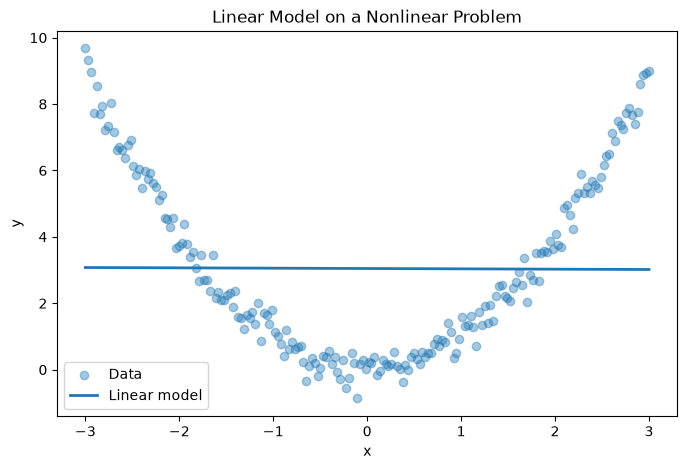

In [5]:
linear_model.eval()

with torch.no_grad():
    linear_predictions = linear_model(x)

plt.figure(figsize=(8, 5))

plt.scatter(
    x.numpy(),
    y.numpy(),
    alpha=0.4,
    label="Data"
)

plt.plot(
    x.numpy(),
    linear_predictions.numpy(),
    linewidth=2,
    label="Linear model"
)

plt.xlabel("x")
plt.ylabel("y")
plt.title("Linear Model on a Nonlinear Problem")
plt.legend()
plt.show()

## Linear Baseline — Interpretation

The trained linear model produced approximately:

```text
loss   = 7.3367
weight = -0.0099
bias   = 3.0462
```

The learned weight is very close to zero, so the prediction is approximately:

$$
\hat{y} \approx 3.05
$$

which appears as an almost horizontal line.

### Why did the slope approach zero?

The target relationship is approximately:

$$
y = x^2
$$

which is symmetric around $x=0$.

For example:

```text
x = -3 → y ≈ 9
x = +3 → y ≈ 9

x = -2 → y ≈ 4
x = +2 → y ≈ 4
```

A positive linear slope could improve the fit on one side of the parabola while
making the opposite side worse.

A negative slope would have the opposite problem.

Because the dataset is roughly symmetric, the best linear compromise has:

```text
w ≈ 0
```

and uses the bias to place a horizontal line near the average vertical level of
the observations.

### Optimization vs representation

This experiment illustrates an important distinction:

```text
optimization
→ find the best parameters available for a model

representation / capacity
→ determine what kinds of functions that model can express
```

The optimizer successfully reduced the loss.

The problem is that no choice of `w` and `b` can transform:

$$
wx+b
$$

into the curved function:

$$
x^2
$$

Therefore:

> **A well-optimized model can still perform poorly when the model class cannot represent the underlying relationship.**

Before changing optimizers or training longer, we should first ask whether the
model has enough representational capacity for the problem.

## Why Stacking Linear Layers Is Not Enough

A natural idea is to add more linear layers.

For example:

$$
h = xW_1+b_1
$$

followed by:

$$
\hat{y} = hW_2+b_2
$$

Substituting the first equation into the second gives:

$$
\hat{y}
=
(xW_1+b_1)W_2+b_2
$$

Expanding:

$$
\hat{y}
=
xW_1W_2+b_1W_2+b_2
$$

Define:

$$
W' = W_1W_2
$$

and:

$$
b' = b_1W_2+b_2
$$

Then:

$$
\hat{y}=xW'+b'
$$

which is still only a linear transformation.

Therefore:

```text
Linear
→ Linear
→ Linear
```

can always collapse into:

```text
one Linear transformation
```

No matter how many purely linear layers we stack, the overall function remains
linear.

To represent genuinely nonlinear relationships, we need to introduce a
**nonlinear activation function** between layers.

The basic neural-network pattern becomes:

```text
input
↓
linear transformation
↓
nonlinear activation
↓
linear transformation
↓
output
```

The nonlinear activation is what prevents the entire network from collapsing
into a single linear transformation.

## Introducing ReLU

A common activation function is the Rectified Linear Unit, or **ReLU**:

$$
\operatorname{ReLU}(z)=\max(0,z)
$$

It behaves as:

```text
negative input → 0
positive input → unchanged
```

Examples:

```text
ReLU(-3) = 0
ReLU(-1) = 0
ReLU(0)  = 0
ReLU(2)  = 2
ReLU(5)  = 5
```

ReLU is simple, but critically it is **nonlinear**.

Once it is inserted between linear transformations:

```text
Linear
↓
ReLU
↓
Linear
```

the entire network can no longer be collapsed into one linear transformation.

This allows the model to represent much richer functions.

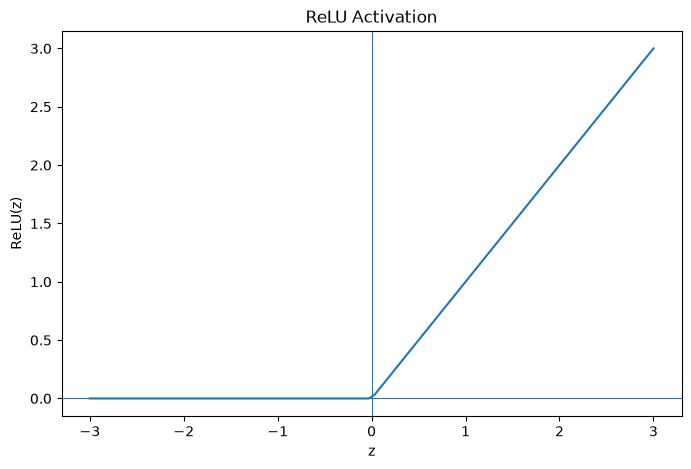

In [8]:
# Example inputs spanning negative and positive values
z = torch.linspace(-3, 3, 100)

# Apply ReLU
relu_z = torch.relu(z)

plt.figure(figsize=(8, 5))

plt.plot(
    z.numpy(),
    relu_z.numpy()
)

plt.axhline(0, linewidth=0.8)
plt.axvline(0, linewidth=0.8)

plt.xlabel("z")
plt.ylabel("ReLU(z)")
plt.title("ReLU Activation")
plt.show()

## Building a Two-Layer Neural Network Manually

We now build a small network with one hidden layer.

The structure is:

```text
input
↓
linear transformation
↓
ReLU
↓
linear transformation
↓
prediction
```

For one input feature and `H` hidden units:

```text
x
[N, 1]

↓ W1 + b1

hidden pre-activation
[N, H]

↓ ReLU

hidden activation
[N, H]

↓ W2 + b2

prediction
[N, 1]
```

We will use:

```text
H = 16
```

so each scalar input is transformed into 16 hidden features.

The parameters are:

```text
W1 → [1, 16]
b1 → [16]

W2 → [16, 1]
b2 → [1]
```

The first layer expands:

```text
1 feature
→ 16 learned hidden features
```

The second layer combines those hidden features into:

```text
1 output
```

This is the first point where tensor-shape reasoning becomes essential.

In [9]:
# Number of hidden units
hidden_size = 16

torch.manual_seed(42)

# First linear transformation: 1 input feature -> 16 hidden features
W1 = torch.randn(
    1,
    hidden_size,
    requires_grad=True
)

b1 = torch.zeros(
    hidden_size,
    requires_grad=True
)

# Second linear transformation: 16 hidden features -> 1 output
W2 = torch.randn(
    hidden_size,
    1,
    requires_grad=True
)

b2 = torch.zeros(
    1,
    requires_grad=True
)

print("x shape: ", x.shape)
print("W1 shape:", W1.shape)
print("b1 shape:", b1.shape)
print("W2 shape:", W2.shape)
print("b2 shape:", b2.shape)

x shape:  torch.Size([200, 1])
W1 shape: torch.Size([1, 16])
b1 shape: torch.Size([16])
W2 shape: torch.Size([16, 1])
b2 shape: torch.Size([1])


In [10]:
# First linear transformation
z1 = x @ W1 + b1

# Nonlinear activation
h1 = torch.relu(z1)

# Second linear transformation
y_pred = h1 @ W2 + b2

print("z1 shape:", z1.shape)
print("h1 shape:", h1.shape)
print("y_pred shape:", y_pred.shape)

z1 shape: torch.Size([200, 16])
h1 shape: torch.Size([200, 16])
y_pred shape: torch.Size([200, 1])


## Shape Interpretation

The first transformation is:

```text
x
[200, 1]

@

W1
[1, 16]

=

z1
[200, 16]
```

Each of the 200 examples now has 16 hidden features.

The bias:

```text
b1
[16]
```

is broadcast across all 200 examples.

ReLU does not change the shape:

```text
z1
[200, 16]

→ ReLU →

h1
[200, 16]
```

The second transformation is:

```text
h1
[200, 16]

@

W2
[16, 1]

=

prediction
[200, 1]
```

So the network transforms:

```text
1 input feature
→ 16 hidden features
→ 1 output
```

The hidden representation gives the network more flexibility than a single
linear model.

## Training the Manual Neural Network

The network currently has four learnable parameter tensors:

```text
W1
b1
W2
b2
```

The training loop is still the same:

```text
forward
→ loss
→ backward
→ update
→ clear gradients
→ repeat
```

The only difference from linear regression is that the forward pass now contains
multiple transformations and a nonlinear activation.

We will train the network using Mean Squared Error.

In [11]:
# Learning-rate and training settings
learning_rate = 0.01
epochs = 2000

manual_nn_losses = []

for epoch in range(epochs):
    # -------------------------
    # Forward pass
    # -------------------------
    z1 = x @ W1 + b1
    h1 = torch.relu(z1)
    y_pred = h1 @ W2 + b2

    # -------------------------
    # Loss
    # -------------------------
    loss = ((y_pred - y) ** 2).mean()
    manual_nn_losses.append(loss.item())

    # -------------------------
    # Backward pass
    # -------------------------
    loss.backward()

    # -------------------------
    # Parameter update
    # -------------------------
    with torch.no_grad():
        W1 -= learning_rate * W1.grad
        b1 -= learning_rate * b1.grad
        W2 -= learning_rate * W2.grad
        b2 -= learning_rate * b2.grad

    # -------------------------
    # Clear gradients
    # -------------------------
    W1.grad.zero_()
    b1.grad.zero_()
    W2.grad.zero_()
    b2.grad.zero_()

    if epoch % 200 == 0:
        print(
            f"Epoch {epoch:4d} | "
            f"Loss: {loss.item():.6f}"
        )

Epoch    0 | Loss: 55.635567
Epoch  200 | Loss: 0.410031
Epoch  400 | Loss: 0.343411
Epoch  600 | Loss: 0.286464
Epoch  800 | Loss: 0.244834
Epoch 1000 | Loss: 0.216325
Epoch 1200 | Loss: 0.194506
Epoch 1400 | Loss: 0.175078
Epoch 1600 | Loss: 0.158037
Epoch 1800 | Loss: 0.147204
